In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/clean_orders.csv', parse_dates=['order_date', 'ship_date', 'order_month'])
d = df[(df['order_month'] >= '2015-01-01') & (df['order_month'] <= '2017-09-01')]
months = pd.date_range('2015-01-01', '2017-09-01', freq='MS')

A_cats = ['Fishing', 'Cleats', 'Camping & Hiking', 'Cardio Equipment',
          "Women's Apparel", 'Water Sports', 'Indoor/Outdoor Games']

series = (d[d['category'].isin(A_cats)]
            .groupby(['category', 'order_month'])['qty'].sum()
            .unstack(0).reindex(months, fill_value=0))
print(series.shape)
series.head()

(33, 7)


category,Camping & Hiking,Cardio Equipment,Cleats,Fishing,Indoor/Outdoor Games,Water Sports,Women's Apparel
2015-01-01,402,1154,2281,520,1788,453,1769
2015-02-01,376,922,1899,426,1520,407,1696
2015-03-01,393,1101,2288,506,1835,449,1916
2015-04-01,399,1023,2062,504,1693,468,1842
2015-05-01,370,1334,2138,487,1596,472,1830


In [2]:
train, test = series.iloc[:27], series.iloc[27:]   # last 6 months held out

def metrics(actual, pred):
    err = actual - pred
    return pd.Series({'MAPE_%': (err.abs() / actual).mean() * 100,
                      'RMSE': np.sqrt((err**2).mean()),
                      'Bias': (pred - actual).mean()})   # positive = over-forecast

results = {}
for c in series.columns:
    results[(c, 'Naive')] = metrics(test[c], pd.Series(train[c].iloc[-1], index=test.index))
    results[(c, 'MA3')] = metrics(test[c], pd.Series(train[c].iloc[-3:].mean(), index=test.index))
    results[(c, 'MA6')] = metrics(test[c], pd.Series(train[c].iloc[-6:].mean(), index=test.index))

res = pd.DataFrame(results).T
print(res.round(2))
print()
print(res.groupby(level=1)['MAPE_%'].mean().round(2))

                            MAPE_%    RMSE    Bias
Camping & Hiking     Naive    7.46   33.03   29.50
                     MA3      3.64   19.42   12.50
                     MA6      2.93   15.53    4.50
Cardio Equipment     Naive    4.58   57.47   13.33
                     MA3     11.00  124.58  111.33
                     MA6      9.14  107.65   92.00
Cleats               Naive    5.20  149.44   57.83
                     MA3      5.49  141.13   30.50
                     MA6      5.37  154.33   69.50
Fishing              Naive    4.00   25.12  -19.00
                     MA3      6.64   38.36  -34.67
                     MA6      4.27   26.80  -21.17
Indoor/Outdoor Games Naive    4.37   91.67   31.83
                     MA3      5.46  106.67   63.17
                     MA6      8.30  154.74  128.67
Water Sports         Naive    5.05   25.50   13.67
                     MA3      5.24   31.50  -23.00
                     MA6      4.49   27.85  -17.67
Women's Apparel      Naive    9

In [3]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
import warnings
warnings.filterwarnings('ignore')

preds = {}
for c in series.columns:
    ses = SimpleExpSmoothing(train[c], initialization_method='estimated').fit()
    preds[(c, 'SES')] = ses.forecast(6)

    hw = ExponentialSmoothing(train[c], trend='add', seasonal='add',
                              seasonal_periods=12, initialization_method='estimated').fit()
    preds[(c, 'Holt-Winters')] = hw.forecast(6)

for (c, m), p in preds.items():
    results[(c, m)] = metrics(test[c], pd.Series(p.values, index=test.index))

res = pd.DataFrame(results).T
summary = res.groupby(level=1).mean().round(2).sort_values('MAPE_%')
print(summary)

              MAPE_%   RMSE   Bias
SES             4.62  71.63  28.99
MA6             5.63  85.69  48.43
Naive           5.78  81.27  42.50
Holt-Winters    5.88  83.37  31.85
MA3             6.34  86.32  40.02


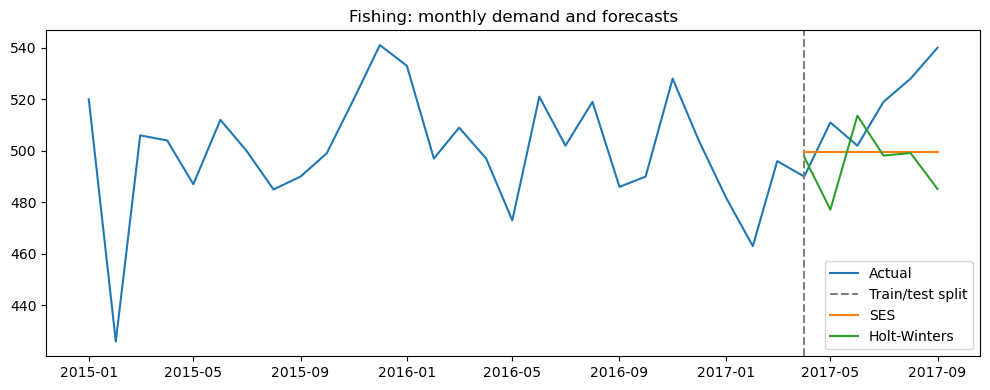

In [4]:
import matplotlib.pyplot as plt

c = 'Fishing'
plt.figure(figsize=(10, 4))
plt.plot(series[c], label='Actual')
plt.axvline(test.index[0], color='grey', linestyle='--', label='Train/test split')
plt.plot(test.index, preds[(c, 'SES')].values, label='SES')
plt.plot(test.index, preds[(c, 'Holt-Winters')].values, label='Holt-Winters')
plt.title(f'{c}: monthly demand and forecasts')
plt.legend(); plt.tight_layout(); plt.show()

In [5]:
print(res.xs('SES', level=1).round(2))
print()
print((res['MAPE_%'].unstack(1)
         .sub(res['MAPE_%'].unstack(1)['Naive'], axis=0)
         .round(2)))

                      MAPE_%    RMSE   Bias
Camping & Hiking        3.58   16.19  -6.43
Cardio Equipment        5.41   77.06  53.04
Cleats                  5.21  150.70  61.02
Fishing                 3.54   22.50 -15.37
Indoor/Outdoor Games    6.08  115.84  77.65
Water Sports            4.45   27.64 -17.33
Women's Apparel         4.08   91.51  50.33

                      Holt-Winters   MA3   MA6  Naive   SES
Camping & Hiking             -3.54 -3.82 -4.53    0.0 -3.88
Cardio Equipment              2.05  6.42  4.56    0.0  0.83
Cleats                        0.62  0.28  0.16    0.0  0.01
Fishing                       1.03  2.64  0.27    0.0 -0.46
Indoor/Outdoor Games          1.89  1.09  3.92    0.0  1.71
Water Sports                  1.48  0.19 -0.56    0.0 -0.60
Women's Apparel              -2.83 -2.81 -4.83    0.0 -5.69
